In [180]:
pip install engineering_notation

In [181]:
import numpy as np
import matplotlib.pyplot as plt
from engineering_notation import EngNumber
from matplotlib.widgets import Slider, Button
from matplotlib.colors import Normalize
import matplotlib.cm as cm
import cmath
import matplotlib.colors as mcolors
from matplotlib.ticker import (MultipleLocator, FormatStrFormatter,AutoMinorLocator)
import pandas as pd

In [182]:
import openpyxl
from openpyxl import Workbook
from openpyxl.styles import Font
from openpyxl.styles.colors import Color
from openpyxl.styles.alignment import Alignment
from openpyxl.styles import PatternFill, Border, Side, Alignment, Protection, Font

importando arquivo externo Excel

In [183]:
from google.colab import files
#uploaded = files.upload()
import io
df = pd.read_excel(io.BytesIO(uploaded['teste.xlsx']))
flagDessintonia      =  df['box'][0]
flagPerdasIndutor    =  df['box'][1] 
flagFatorDeQualidade =  df['box'][2]   
flagImpedanciaTrafo  =  df['box'][3]  
flagCorrenteFiltro   =  df['box'][4]  

# Dados do Transformador e do Filtro

# Dados Básicos

## Rede

In [184]:
V_fund = df.values[3,7]
f_fund = 60
w_fund = 2*np.pi*f_fund
EngNumber(V_fund)

34.50k


## Potência reativa a corrigir em $60\,\rm{Hz}$

In [185]:
Q_filtro = df.values[0,4]
X_F      = V_fund**2 / Q_filtro
print(EngNumber(Q_filtro))
print(EngNumber(X_F))

4M
297.56


## Indutância e Capacitância do Filtro

In [186]:
h_filtrar = 5
flagDessintonia = True
if( flagDessintonia == True ):
    d = df['valor'][0]
else:
    d = 0
h_0 = (1-d)*h_filtrar
h02 = h_0**2

X_L =  1/(h02-1) * X_F
L   =  X_L / w_fund

X_C = h02/(h02-1) * X_F
C   = 1  / ( X_C* w_fund )

f_max = ( 1 / np.sqrt(L*C) ) / ( 2 * np.pi )
print(EngNumber(f_max),'Hz')
print(EngNumber(L),'H')
print(EngNumber(C),'F')

294 Hz
34.30m H
8.54u F


## Dados do indutor, se fornecido

In [187]:
if( flagPerdasIndutor == True ):
    P_perdasIndutor = df['valor'][1]
    I_indutor = 572
    R_indutor = P_perdasIndutor / I_indutor**2
else:
    R_indutor = 1e-6
EngNumber(R_indutor)

1u

## Fator de Qualidade e Amortecimento (Resistência do Filtro)

In [188]:
Z0 = np.sqrt(L/C)
if( flagFatorDeQualidade == True ):
    FQual = df['valor'][2]
    R = Z0 / FQual
else:
    R  = R_indutor
    FQual = Z0 / R
FQual
print(FQual)
print(EngNumber(R),'ohm')

80.0
792.08m ohm


## Dados do transformador, se fornecido

In [189]:
if( flagImpedanciaTrafo == True ):
    S_trafo     = df.values[3,4]
    V_fund      = df.values[3,7]
    Z_baseTrafo = V_fund**2 / S_trafo
    R_trafo_pu  = df.values[3, 13]
    X_trafo_pu  = df.values[3, 15]
    Z_trafo     = (R_trafo_pu + 1j*X_trafo_pu) * Z_baseTrafo #######################
else:
    Z_baseTrafo = 20
    R_trafo_pu  = 1e-3
    X_trafo_pu  = 5/100
    Z_trafo     = 1.0*(R_trafo_pu + 1j*X_trafo_pu) * Z_baseTrafo #######################
Z_trafo
print('Z_trafo =', EngNumber(np.real(Z_trafo)),'+ j',EngNumber(np.imag(Z_trafo)),' ohms' )
print('Z_baseTrafo =', Z_baseTrafo)

Z_trafo = 23.80m + j 1.21  ohms
Z_baseTrafo = 19.8375


## Variação com a frequência

In [190]:
nharm = 25 ### pensar em deixar automático ###
f = np.arange(f_fund, (nharm+1)*f_fund, f_fund)
f = np.round(f,4) # não tire este ROUND
w = 2*np.pi*f

### Filtro Série Sintonizado (single tuned)

In [191]:
Zfiltro = R + 1j*w*L + 1/(1j*w*C)
Zmod    = np.abs(Zfiltro)
Zang    = np.angle(Zfiltro, deg=True)

### Transformador

In [192]:
X_trafo     = ( np.imag(Z_trafo)/w_fund ) * w
R_trafo     =   np.real(Z_trafo)          * np.ones(len(w))
Z_trafoFreq =   R_trafo + 1j*X_trafo

## Filtro em paralelo com o transformador

In [193]:
Y_trafoFiltro = 1 / Zfiltro + 1 / Z_trafoFreq
Z_trafoFiltro = 1 / Y_trafoFiltro

Se não tivesse filtro, apenas capacitores para correção do fator de deslocamento

In [194]:
Y_trafoCapaci = 1j*w*C + 1/Z_trafoFreq
Z_trafoCapaci = 1 / Y_trafoCapaci

## Correntes harmônicas prezumidas

#### Inicializações de arrays

In [195]:
vharmCF    = np.zeros((len(f)), dtype=np.complex_)
vharmSF    = np.zeros((len(f)), dtype=np.complex_)
iharmF     = np.zeros((len(f)), dtype=np.complex_)
iharmTCF   = np.zeros((len(f)), dtype=np.complex_)

In [196]:
I_baseTrafo   = S_trafo / ( V_fund * np.sqrt(3) )
harm       = np.arange(0, len(f), 1) + 1  
if( flagCorrenteFiltro == True ):
        mod = pd.to_numeric( df.values[4, 4:] )
        ang = np.pi/180 * pd.to_numeric( df.values[5, 4:] )
        iharm = mod * ( np.cos(ang) +1j*np.sin(ang) )
else:   
    
    iharm      = I_baseTrafo / harm
    iharm[0]   = S_trafo / ( np.sqrt(3) * V_fund )
    iharm[5-1] = 0.5 * I_baseTrafo

In [197]:
np.abs(iharm)

array([1004.08742468,   99.        ,   68.        ,   70.        ,
        502.04371234,   78.        ,   56.        ,    7.        ,
          6.22222222,    5.6       ,    5.09090909,    4.66666667,
          4.30769231,    4.        ,    3.73333333,    3.5       ,
          3.29411765,    3.11111111,    2.94736842,    2.8       ,
          2.66666667,    2.54545455,    2.43478261,    2.33333333,
          2.24      ])

In [198]:
Z_trafoFiltro.shape

(25,)

In [199]:
vharmCF    = iharm * Z_trafoFiltro
vharmCF[0] = ( V_fund / np.sqrt(3) )
vharmSF  = iharm * Z_trafoCapaci
vharmSF[0] = ( V_fund / np.sqrt(3) )
  
iharmF    = vharmCF / Zfiltro
iharmF[0] =  ( V_fund / np.sqrt(3) ) / Zfiltro[0]
iharmTCF = vharmCF / Z_trafoFreq

itotalfiltro = np.sqrt( np.dot(np.abs(iharmF), np.abs(iharmF)) )
np.abs(vharmCF)/V_fund

array([0.57735027, 0.00707756, 0.00758068, 0.01207541, 0.027283  ,
       0.01281692, 0.01161825, 0.00170839, 0.00173365, 0.00174886,
       0.00175888, 0.0017659 , 0.00177104, 0.00177493, 0.00177796,
       0.00178037, 0.00178231, 0.00178391, 0.00178525, 0.00178637,
       0.00178732, 0.00178814, 0.00178885, 0.00178947, 0.00179001])

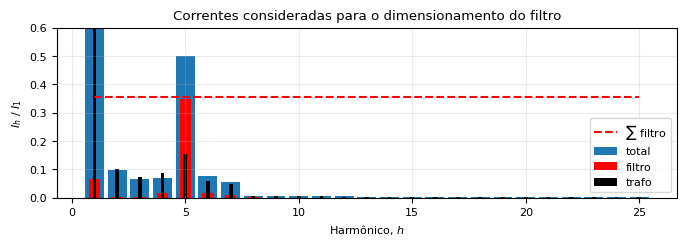

In [200]:
fig = plt.figure(dpi=100, figsize=(16/2,9/4))
plt.grid(alpha=0.25)
plt.bar (harm, np.abs(iharm)/I_baseTrafo, 50/f_fund, label='total')
plt.bar (harm, np.abs(iharmF)/I_baseTrafo, 30/f_fund, label='filtro', color='red')
plt.plot(harm, itotalfiltro*np.ones(len(harm))/I_baseTrafo, label='$\sum$ filtro', ls="--", color='red')
plt.bar (harm, np.abs(iharmTCF)/I_baseTrafo, 10/f_fund, label='trafo', color='black')
plt.title('Correntes consideradas para o dimensionamento do filtro')
plt.legend(loc='best')
plt.xlabel('Harmônico, $h$')
plt.ylabel('$I_h$ / $I_1$')
plt.ylim(0,0.6)
plt.show()
fig.savefig("Correntes consideradas para o dimensionamento do filtro.png", dpi=100)

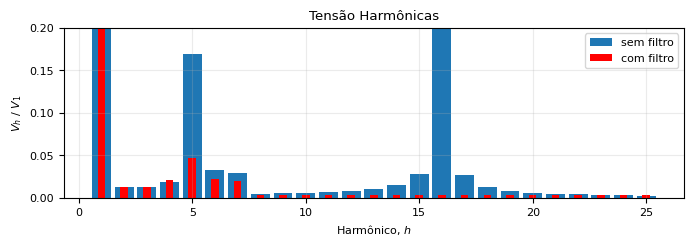

In [201]:
fig = plt.figure(dpi=100, figsize=(16/2,9/4))
plt.bar (harm, np.abs(vharmSF)/( V_fund/np.sqrt(3) ), 50/f_fund, label='sem filtro')
plt.bar (harm, np.abs(vharmCF)/( V_fund/np.sqrt(3) ), 20/f_fund, label='com filtro', color= 'red')
plt.grid(alpha=0.25)
plt.legend()
plt.title('Tensão Harmônicas')
plt.xlabel('Harmônico, $h$')
plt.ylabel('$V_h$ / $V_1$')
plt.ylim(0, 0.2)
plt.show()
fig.savefig("Quedas de Tensão Harmônicas", dpi=100)
#files.download("Quedas de Tensão Harmônicas.png") 

### Análise do Filtro

In [202]:
Ifiltro     =   iharmF
Vindutor    =   1j * w * L * Ifiltro
Vcapacitor  =   1/( 1j * w * C) * Ifiltro
Vresistor   =    R * Ifiltro

## Potências nos Elementos do Filtro Série

In [203]:
Qcap = 3 * Vcapacitor * np.conj(Ifiltro)
Qind = 3 * Vindutor   * np.conj(Ifiltro)
Pfil = 3 * Vresistor  * np.conj(Ifiltro)
Pfil = np.real( Pfil        )
Qfil = np.imag( Qcap + Qind )

print('Qfil = ', EngNumber(       (Qfil[0])))
print('Qind = ', EngNumber(np.imag(Qind[0])))
print('Qcap = ', EngNumber(np.imag(Qcap[0])))

Qfil =  -4M
Qind =  173.84k
Qcap =  -4.17M


## Saídas

In [204]:
RRRR = str(EngNumber(R))+'\u2126'
LLLL = str(EngNumber(L))+'H'
CCCC = str(EngNumber(C))+'F'


Vtotal = Vcapacitor+Vindutor+Vresistor

VFm = EngNumber(np.abs(Vtotal[0]))
VRm = EngNumber(np.abs(Vresistor[0]))
VLm = EngNumber(np.abs(Vindutor[0]))
VCm = EngNumber(np.abs(Vcapacitor[0]))

VFa = '\u2221 '+str( EngNumber(np.round(np.angle(Vtotal[0],deg=True),3)) ) + '°'
VRa = '\u2221 '+str( EngNumber(np.round(np.angle(Vresistor[0],deg=True),3)) ) + '°'
VLa = '\u2221 '+str( EngNumber(np.round(np.angle(Vindutor[0],deg=True),3)) ) + '°'
VCa = '\u2221 '+str( EngNumber(np.round(np.angle(Vcapacitor[0],deg=True),3)) ) + '°'


IFm = EngNumber(np.abs(Ifiltro[0]))
IRm = EngNumber(np.abs(Ifiltro[0]))
ILm = EngNumber(np.abs(Ifiltro[0]))
ICm = EngNumber(np.abs(Ifiltro[0]))

IFa = '\u2221 '+str( EngNumber(np.round(np.angle(Ifiltro[0],deg=True),3)) ) + '°'
IRa = '\u2221 '+str( EngNumber(np.round(np.angle(Ifiltro[0],deg=True),3)) ) + '°'
ILa = '\u2221 '+str( EngNumber(np.round(np.angle(Ifiltro[0],deg=True),3)) ) + '°'
ICa = '\u2221 '+str( EngNumber(np.round(np.angle(Ifiltro[0],deg=True),3)) ) + '°'



Pfm = EngNumber(Pfil[0])
QFm = EngNumber(Qfil[0])
QLm = EngNumber(np.imag(Qind[0]))
QCm = EngNumber(np.imag(Qcap[0]))




dataFiltroSerie = { 'Local'         : ['Resistência',  'Indutância',    'Capacitância',     'Filtro'],   #, 'Vres','Vcap','Vind','Vtot','Iser','Sfil'],
                    'RLC'           : [RRRR,            LLLL,           CCCC,               '----'],
                    'Vmod [V]'      : [VRm,             VLm,            VCm,                VFm],
                    'Vang [°]'      : [VRa,             VLa,            VCa,                VFa],
                    'Imod [A]'      : [IRm,             ILm,            ICm,                IFm],
                    'Iang [°]'      : [IRa,             IRa,            ILa,                ICa],
                    'S [VA]'        : [Pfm,             QLm,            QCm,                QFm]
                   
                    }

Gradezas = pd.DataFrame(dataFiltroSerie, columns = ['Local', 'RLC', 'Vmod [V]', 'Vang [°]', 'Imod [A]', 'Iang [°]', 'S [VA]'])




Gradezas.to_excel('RelatorioSerie.xlsx', sheet_name = 'Serie')

print('==========================================================')
print('     No circuito RLC série Q\u2080 =',FQual,' \u03B6 =',EngNumber(1/(2*FQual)) )
print('==========================================================')
print(Gradezas)
#("RelatorioSerie.xlsx")

     No circuito RLC série Q₀ = 80.0  ζ = 6.25m
          Local       RLC Vmod [V]   Vang [°] Imod [A]  Iang [°]   S [VA]
0   Resistência  792.08mΩ    53.02   ∡ 89.85°    66.94  ∡ 89.85°   10.65k
1    Indutância   34.30mH   865.65  ∡ 179.85°    66.94  ∡ 89.85°  173.84k
2  Capacitância    8.54uF   20.78k   ∡ -153m°    66.94  ∡ 89.85°   -4.17M
3        Filtro      ----   19.92k       ∡ 0°    66.94  ∡ 89.85°      -4M


## Largura de faixa

In [205]:
w0 = 1 / np.sqrt(L*C)
Q0 = w0*L/R
BW = w0 / Q0
w1 = w0 - BW/2
w2 = w0 + BW/2

print('======================================================================')
print('   R = ',EngNumber(R),'\u2126    Q0 = ', EngNumber(FQual),'  \u03B6 = ',EngNumber(1/(2*FQual)) )
print('======================================================================')    
print('Fator de qualidade           = ', EngNumber(Q0) )
print('Fator de amortecimento       = ', EngNumber(1/(2*Q0)) )
print('Frequência de ressonância    = ', EngNumber(w0/(2*np.pi)), 'Hz')
print('Frequências de meia potência = ', EngNumber(w1/(2*np.pi)), 'Hz e ', EngNumber(w2/(2*np.pi)), 'Hz')
print('======================================================================')

   R =  792.08m Ω    Q0 =  80   ζ =  6.25m
Fator de qualidade           =  80
Fator de amortecimento       =  6.25m
Frequência de ressonância    =  294 Hz
Frequências de meia potência =  292.16 Hz e  295.84 Hz


# Diagrama de Bode

In [206]:
f = np.arange(f_fund, nharm*f_fund, 0.1)
f = np.round(f,4) # não tire este ROUND se houverem frequencias interharmônicas
w = 2*np.pi*f

Zfiltro = R + 1j*w*L + 1/(1j*w*C)
Zmod    = np.abs(Zfiltro)
Zang    = np.angle(Zfiltro, deg=True)

X_trafo     = ( np.imag(Z_trafo)/w_fund ) * w
R_trafo     =   np.real(Z_trafo)          * np.ones(len(w))
Z_trafoFreq =   R_trafo + 1j*X_trafo

Y_filtro      = 1 / Zfiltro
Y_trafo       = 1 / Z_trafoFreq
Y_trafoFiltro = Y_filtro + Y_trafo
Z_trafoFiltro = 1 / Y_trafoFiltro

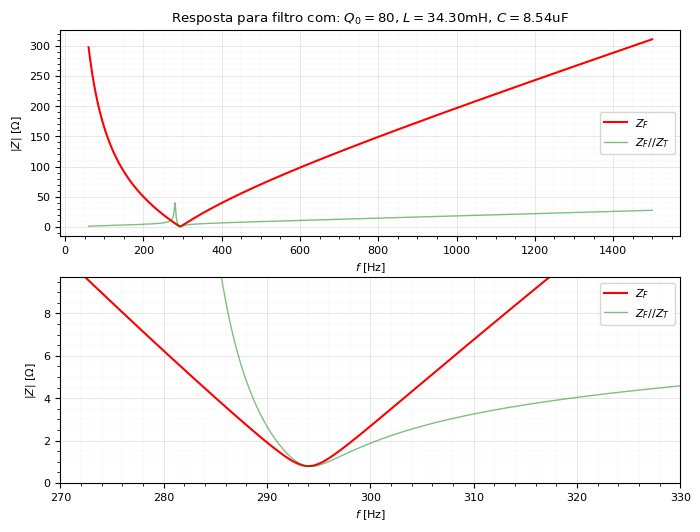

In [207]:
fig, axs = plt.subplots(2, 1)
fig.dpi = 100
fig.set_size_inches(16/2, 12/2)
plt.rcParams.update({'font.size': 8})

leg = '$Z_{F}$'
axs[0].plot(f, Zmod, label=leg, color='red')
leg = '$Z_{F}$//$Z_{T}$'
axs[0].plot(f, np.abs(Z_trafoFiltro), label=leg, lw=1.0, alpha=0.5, color='green', ls='-')
axs[0].grid(which='major', color='#DDDDDD', linewidth=0.5)
axs[0].minorticks_on()
axs[0].grid(which='minor', color='#EEEEEE', linewidth=0.25)
axs[0].set_ylabel('$|Z|$ [$\Omega$]')
#axs[1].plot(f, np.abs(Z_trafoFreq), label='trafo', ls='--', color='black')
axs[0].set_xlabel('$f$ [Hz]')
# axs[0].set_ylim(0, np.abs(2*Zfiltro[0]))
axs[0].legend()
leg = 'Resposta para filtro com: $Q_0=$'+str(EngNumber(FQual))+', $L=$'+str(EngNumber(L))+'H, $C=$'+str(EngNumber(C))+'F'
axs[0].set_title(leg)


leg = '$Z_{F}$'
axs[1].plot(f, Zmod, label=leg, color='red')
leg = '$Z_{F}$//$Z_{T}$'
axs[1].plot(f, np.abs(Z_trafoFiltro), label=leg, lw=1.0, alpha=0.5, color='green', ls='-')
axs[1].grid(which='major', color='#DDDDDD', linewidth=0.5)
axs[1].minorticks_on()
axs[1].grid(which='minor', color='#EEEEEE', linewidth=0.25)
axs[1].set_ylim(0, np.abs(8*Z_trafoFiltro[0]))
axs[1].set_xlim(f_fund*(h_filtrar-1/2), f_fund*(h_filtrar+1/2))
axs[1].set_ylabel('$|Z|$ [$\Omega$]')
#axs[1].plot(f, np.abs(Z_trafoFreq), label='trafo', ls='--', color='black')
axs[1].set_xlabel('$f$ [Hz]')
axs[1].legend(loc='best')
f1 = w1/(2*np.pi)
f2 = w2/(2*np.pi)
fig.show()
fig.savefig("Resposta do Filtro.png", dpi=100)
#files.download("Resposta do Filtro.png") 

# Relatório Excel


In [208]:

wb = Workbook()

# grab the active worksheet
ws = wb.active
ws.sheet_view.showGridLines = False
ws.title = 'Filtro Série'

# Data can be assigned directly to cells
ws.column_dimensions['A'].width = 5
ws.column_dimensions['B'].width = 30
ws.column_dimensions['C'].width = 15
ws.column_dimensions['D'].width = 15
ws.column_dimensions['E'].width = 15


ws['A1'] = 'Filtro Série'
ws['A1'].font = Font(size=20)
ws['A2'].hyperlink = 'https://dax.energy/'
ws['A2'].font = Font(color='060CFA')


val = Gradezas['RLC']
val = list(val)
ws['A4']  = 'Componentes do Filtro'
ws['A4'].font = Font(size=15)
ws['B6']  = 'Resistência:  '+val[0]
ws['B7']  = 'Indutância:   '+val[1]
ws['B8'] = 'Capacitância: '+val[2]
ws['C6'] = 'Fator de Qualidade:     '+str(EngNumber(FQual))
ws['C7'] = 'Fator de Amortecimento: '+str(EngNumber(1/(2*FQual)))
ws['C8'] = 'Sintonizado em: '+str(EngNumber(f_max))+'Hz'


ws['A10']  = 'Grandezas Elétricas no Filtro'
ws['A10'].font = Font(size=15)

ws['B13'] = 'Corrente no Indutor: '
ws['B14'] = 'Tensão no Capacitor: '
ws['B15'] = 'Potência Dissipada: '
ws['B16'] = 'Potência Reativa: '

ws['C12']  = 'Fundamental'
ws['D12']  = 'Total'
ws['E12']  = 'f0 ('+str(EngNumber(h_filtrar*f_fund))+'Hz)'
ws["C12"].alignment = Alignment(horizontal="right")
ws["D12"].alignment = Alignment(horizontal="right")
ws["E12"].alignment = Alignment(horizontal="right")

ws['C13'] = str(EngNumber(np.abs(Ifiltro[0])))+' A'
ws['D13'] = str(EngNumber(itotalfiltro))+' A'
ws['E13'] = str(EngNumber(np.abs(Ifiltro[h_filtrar-1])))+' A'
ws["C13"].alignment = Alignment(horizontal="right")
ws["D13"].alignment = Alignment(horizontal="right")
ws["E13"].alignment = Alignment(horizontal="right")

VVV = np.abs(Vcapacitor)
VVV = np.sqrt(np.dot(VVV, VVV))
ws['C14'] = str(EngNumber(np.abs(Vcapacitor[0])))+' V'
ws['D14'] = str(EngNumber(VVV))+' V'
ws['E14'] = str(EngNumber(np.abs(Vcapacitor[h_filtrar-1])))+' V'
ws["C14"].alignment = Alignment(horizontal="right")
ws["D14"].alignment = Alignment(horizontal="right")
ws["E14"].alignment = Alignment(horizontal="right")

ws['C15'] = str(EngNumber(np.abs(Pfil[0])))+' W'
ws['D15'] = str(EngNumber(np.sum(Pfil)))+' W'
ws['E15'] = str(EngNumber(np.abs(Pfil[h_filtrar-1])))+' W'
ws["C15"].alignment = Alignment(horizontal="right")
ws["D15"].alignment = Alignment(horizontal="right")
ws["E15"].alignment = Alignment(horizontal="right")

ws['C16'] = str(EngNumber(      (Qfil[0])))+' VAr'
ws['D16'] = str(EngNumber(np.sum(Qfil)))+' VAr'
ws['E16'] = str(EngNumber(      (Qfil[h_filtrar-1])))+' VAr'
ws["C16"].alignment = Alignment(horizontal="right")
ws["D16"].alignment = Alignment(horizontal="right")
ws["E16"].alignment = Alignment(horizontal="right")


ws['A19']  = 'Grandezas Elétricas Básicas do Sistema Considerado'
ws['A19'].font = Font(size=15)

ws['B21'] = 'Tensão Fundamental: '+str(EngNumber(V_fund))+'V'
ws['B22'] = 'Frequência Fundamental: '+str(EngNumber(f_fund))+'Hz'
ws['B23'] = 'Potência Reativa Fundamental: '+str(EngNumber(Q_filtro))+'VAr'
ws['B24'] = 'Impedância do Transformador Fundamental: ('+str(EngNumber(np.real(Z_trafo)))+'+ j'+str(EngNumber(np.imag(Z_trafo)))+') Ω'

In [209]:
ws2 = wb.create_sheet("TXT Harmônicas")


ws2.column_dimensions.width = 15


ws2['A1'] = 'harmônico'
ws2['B1'] = 'I_fil_mod'
ws2['C1'] = 'I_fil_ang'

ws2['D1'] = 'V_cap_mod'
ws2['E1'] = 'V_cap_ang'

ws2['F1'] = 'V_ind_mod'
ws2['G1'] = 'V_ind_ang'

ws2['H1'] = 'V_res_mod'
ws2['I1'] = 'V_res_ang'

ws2['K1'] = 'P_fil'
ws2['L1'] = 'Q_fil'
ws2['M1'] = 'Q_cap'
ws2['N1'] = 'Q_ind'

for ii in range(1, nharm+1, 1):
    ws2.cell(row= ii+1 , column = 1, value=harm[ii-1] )
    ws2.cell(row= ii+1 , column = 2, value=np.abs(Ifiltro[ii-1] ))
    ws2.cell(row= ii+1 , column = 3, value=np.angle(Ifiltro[ii-1], deg=True ))

    ws2.cell(row= ii+1 , column = 4, value=np.abs(Vcapacitor[ii-1] ))
    ws2.cell(row= ii+1 , column = 5, value=np.angle(Vcapacitor[ii-1], deg=True ))

    ws2.cell(row= ii+1 , column = 6, value=np.abs(Vindutor[ii-1] ))
    ws2.cell(row= ii+1 , column = 7, value=np.angle(Vindutor[ii-1], deg=True ))

    ws2.cell(row= ii+1 , column = 8, value=np.abs(Vresistor[ii-1] ))
    ws2.cell(row= ii+1 , column = 9, value=np.angle(Vresistor[ii-1], deg=True ))        

    ws2.cell(row= ii+1 , column = 11, value=Pfil[ii-1] )
    ws2.cell(row= ii+1 , column = 12, value=Qfil[ii-1] )
    ws2.cell(row= ii+1 , column = 13, value=np.imag(Qcap[ii-1] ))
    ws2.cell(row= ii+1 , column = 14, value=np.imag(Qind[ii-1] ))

In [210]:
ws3 = wb.create_sheet("Fig_Zxf")
img = openpyxl.drawing.image.Image("Resposta do Filtro.png")
img.anchor = 'G1'
ws3.add_image(img)

ws3.column_dimensions['A'].width = 16
ws3.column_dimensions['B'].width = 16
ws3.column_dimensions['C'].width = 16
ws3.column_dimensions['D'].width = 16
ws3.column_dimensions['E'].width = 16

ws3["A1"].alignment = Alignment(horizontal="right")
ws3["B1"].alignment = Alignment(horizontal="right")
ws3["C1"].alignment = Alignment(horizontal="right")
ws3["D1"].alignment = Alignment(horizontal="right")
ws3["E1"].alignment = Alignment(horizontal="right")

ws3.cell(row= 1 , column = 1, value='frequência [Hz]' )
ws3.cell(row= 1 , column = 2, value='Zfiltro.real' )
ws3.cell(row= 1 , column = 3, value='Zfiltro.imag' )
ws3.cell(row= 1 , column = 4, value='Z_trafoFiltro.real' )
ws3.cell(row= 1 , column = 5, value='Z_trafoFiltro.imag' )

for ii in range(len(f)):
    ws3.cell(row= ii+2 , column = 1, value=f[ii] )
    ws3.cell(row= ii+2 , column = 2, value=np.real(Zfiltro[ii]) )
    ws3.cell(row= ii+2 , column = 3, value=np.imag(Zfiltro[ii]) )
    ws3.cell(row= ii+2 , column = 4, value=np.real(Z_trafoFiltro[ii]) )
    ws3.cell(row= ii+2 , column = 5, value=np.imag(Z_trafoFiltro[ii]) )



ws4 = wb.create_sheet("Fig_Ixf")
img = openpyxl.drawing.image.Image("Correntes consideradas para o dimensionamento do filtro.png")
img.anchor = 'A1'
ws4.add_image(img)

ws5 = wb.create_sheet("Fig_Vxf")
img = openpyxl.drawing.image.Image("Quedas de Tensão Harmônicas.png")
img.anchor = 'A1'
ws5.add_image(img)


# Python types will automatically be converted
import datetime
data_atual = datetime.datetime.now()

ws['E1'] = data_atual
ws["E1"].alignment = Alignment(horizontal="right")
ws['E1'].font = Font(size=8)



thin_border = Border(top=Side(style='thin'))
for ii in range(2,6,1):
    ws.cell(row=12, column=ii).border = thin_border
    ws.cell(row=13, column=ii).border = thin_border
    ws.cell(row=17, column=ii).border = thin_border


# Save the file
wb.save("Relatório DAX -- Divisão de Filtros -- FILTRO SINTONIZADO SÉRIE.xlsx")
files.download("Relatório DAX -- Divisão de Filtros -- FILTRO SINTONIZADO SÉRIE.xlsx") 
data_atual

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

datetime.datetime(2022, 3, 2, 11, 39, 42, 94915)

In [211]:
Gradezas

,Local,RLC,Vmod [V],Vang [°],Imod [A],Iang [°],S [VA]
0,Resistência,792.08mΩ,53.02,∡ 89.85°,66.94,∡ 89.85°,10.65k
1,Indutância,34.30mH,865.65,∡ 179.85°,66.94,∡ 89.85°,173.84k
2,Capacitância,8.54uF,20.78k,∡ -153m°,66.94,∡ 89.85°,-4.17M
3,Filtro,----,19.92k,∡ 0°,66.94,∡ 89.85°,-4M
